# Model initiation

### REVOKED FROM RETRIEVAL PIPELINE

**APPLICABLE: PYTHON <= 3.12 || RUNNING ON WSL**

In [2]:
# Choose Chandra if hardware allows

import os
os.environ["SURYA_INFERENCE_BACKEND"] = "vllm"
os.environ["SURYA_INFERENCE_URL"] = "http://127.0.0.1:8000/v1"
os.environ["SURYA_INFERENCE_PARALLEL"] = "128"
os.environ["SURYA_MAX_TOKENS"] = "64"

from surya.inference import SuryaInferenceManager
from surya.recognition import RecognitionPredictor
from surya.layout import LayoutPredictor, LayoutBox, LayoutResult

manager = SuryaInferenceManager()
rec_predictor = RecognitionPredictor(manager)
lay_predictor = LayoutPredictor(manager)

# Load images

In [3]:
from tqdm import tqdm
from glob import glob

img_paths = glob(r'/mnt/d/AIC_LITE/kfs/Keyframes_L01/keyframes/*/*.jpg')
img_codes = [f'{path.split('/')[-2]}_{path.split('/')[-1].split('.')[0]}' for path in img_paths]

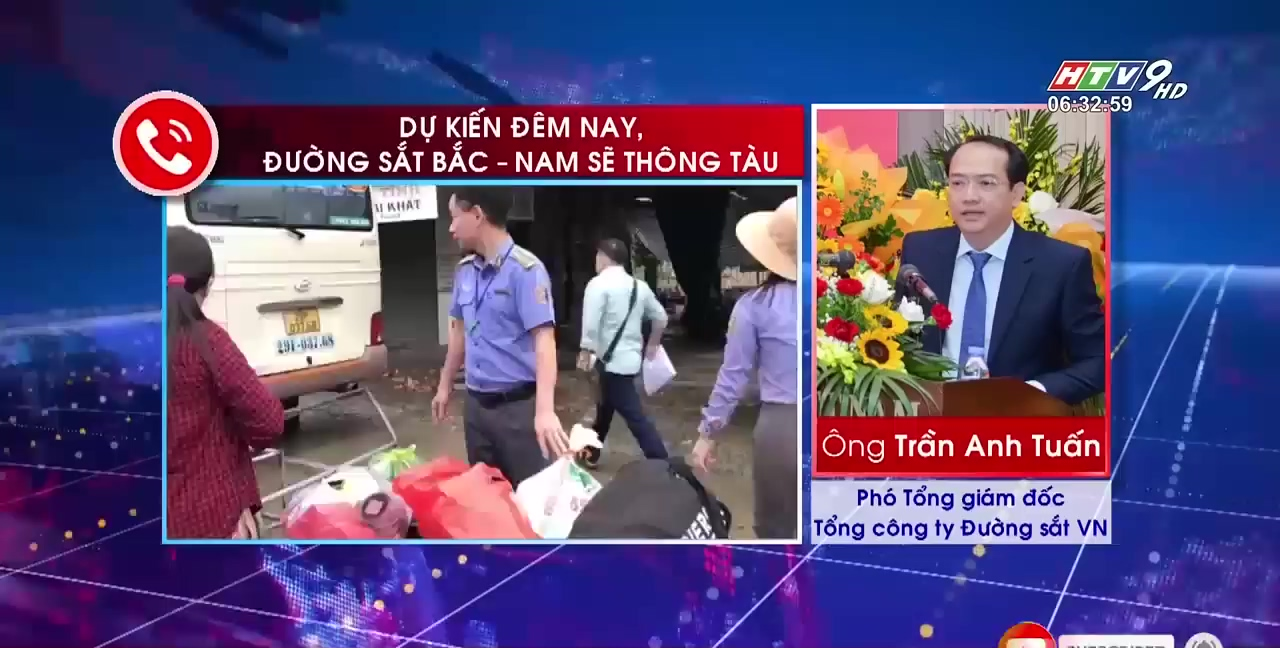

In [ ]:
from PIL import Image

img = Image.open(img_paths[34])
w, h = img.size
cut_rate = 0.1
crop_box = 0, 0, w, h * (1 - cut_rate)
cropped = img.crop(crop_box)
cropped.show()

# Run OCR predictions

In [3]:
# Load checkpoint if found
CKPT = 'L01_V001_001'
try:
    import json
    saved_path = r'/mnt/c/Users/Bui Thien Nghia/Documents/PERSONAL FILES 2/AIC_LAB/additional_data/ocr_saver.json'
    with open(saved_path, 'r') as f:
        ocr_dets = json.load(f)
    for code, _ in list(ocr_dets.items()):
        if not ocr_dets[code]: continue
        CKPT = code
except Exception:
    print('No progress saver found')
    ocr_dets = {code: '' for code in img_codes}
    pass

CKPT

'L01_V011_065'

In [1]:
from bs4 import BeautifulSoup
from PIL import Image
CKPT = 'L01_V001_000'
ocr_dets = {code: '' for code in img_codes}
frozen_data = []

BATCH_SIZE = 128
DET_SCORE_THRESH = 0.78
REC_SCORE_THRESH = 0.85
for i in tqdm(range(0, len(img_paths), BATCH_SIZE)):
    j = len(img_codes) if i + BATCH_SIZE > len(img_codes) else BATCH_SIZE
    paths = [path for path, code in zip(img_paths[i:i+j], img_codes[i:i+j]) if not ocr_dets[code] and code > CKPT]
    codes = [code for code in img_codes[i:i+j] if not ocr_dets[code] and code > CKPT]  
    if not paths: continue

    raws = [Image.open(path) for path in paths]

    lays = lay_predictor(raws)
    valid_paths, valid_codes, valid_lays, valid_raws = [], [], [], []
    for lay, path, code, raw in zip(lays, paths, codes, raws):
        w, h = raw.size
        AREA_THRESH = (w * h) * 0.3 # Maximum OCR det size
        Y_CUTOFF = h * 0.85 # Cover away the distracting headlines

        valid_bboxes = [
            box for box in lay.bboxes if
            box.confidence >= DET_SCORE_THRESH
            and box.label not in ['Image', 'Figure', 'Diagram', 'Picture']
            and (box.polygon[2][0] - box.polygon[0][0]) * (box.polygon[2][1] - box.polygon[0][1]) <= AREA_THRESH
            and box.polygon[0][1] < Y_CUTOFF
        ]

        if not valid_bboxes: continue
        valid_lays.append(valid_bboxes)
        valid_raws.append(raw)
        valid_paths.append(path)
        valid_codes.append(code)

    # print(f'There are {len(valid_codes), len(valid_paths), len(valid_raws), len(valid_lays)} images suitable for recognition')
    if not valid_raws: continue

    # preds = rec_predictor(valid_raws, valid_lays)
    # texts = []
    # for pred in preds:
    #     parses = [
    #         BeautifulSoup(block.html).get_text(separator=' ', strip=True)
    #         for block in pred.blocks if block.confidence >= REC_SCORE_THRESH
    #     ]
    #     full_text = ', '.join([parse for parse in parses if parse])
    #     texts.append(full_text)

    # # # Testing
    # # for text in texts:
    # #     print(text)

    # ocr_dets.update({code: text for code, text in zip(valid_codes, texts)})

NameError: name 'img_codes' is not defined

In [5]:
import json
saved_path = r'/mnt/c/Users/Bui Thien Nghia/Documents/PERSONAL FILES 2/AIC_LAB/additional_data/ocr_saver.json'
with open(saved_path, 'w', encoding='utf-8') as f:
    json.dump(ocr_dets, f, indent=4)

# Testing

In [39]:
# L01_V001_049 is a performance killer
import time
from PIL import Image
from bs4 import BeautifulSoup

i = 48

# Option 1: load WITH crop
raws = []
with Image.open(img_paths[i]) as raw:
    w, h = raw.size
    raws.append(raw.crop((0, 0, w, int(h * 0.85))))

# Option 2: load without crop
# raws = [Image.open(img_paths[i])]

DET_SCORE_THRESH = 0.78
REC_SCORE_THRESH = 0.85

s = time.time()
lays = lay_predictor(raws)
e = time.time()
print(f'Det takes {e - s}s')

valid_bboxes = [
    box for box in lays[0].bboxes if
    box.confidence >= DET_SCORE_THRESH and
    box.label not in ['Image', 'Figure', 'Diagram', 'Picture']
]

if not valid_bboxes:
    print(f'Rec takes 0s')
    raise RuntimeError("No box, no rec")

s = time.time()
preds = rec_predictor(raws, lays)
e = time.time()
print(f'Rec takes {e - s}s')

texts = []
for pred in preds:
    parses = [
        BeautifulSoup(block.html).get_text(separator=' ', strip=True)
        for block in pred.blocks if block.confidence >= REC_SCORE_THRESH
    ]
    # full_text = ', '.join([parse for parse in parses if parse])
    # texts.append(full_text)
    for t in [parse for parse in parses if parse]:
        print(t)

Det takes 3.6444146633148193s
Rec takes 3.6596572399139404s


In [38]:
for bbox in lays[0].bboxes:
    print(bbox.confidence, bbox.polygon)

0.7467062668396262 [[0.0, 0.0], [1280.0, 0.0], [1280.0, 648.0], [0.0, 648.0]]
0.7467062668396262 [[808.96, 55.080000000000005], [1191.68, 55.080000000000005], [1191.68, 359.64000000000004], [808.96, 359.64000000000004]]


In [6]:
lays_dict = lays[34].dict()
print(list(lays_dict.keys()))
for b in lays_dict["bboxes"]:
    print(b)

['bboxes', 'image_bbox', 'raw', 'error']
{'polygon': [[0.0, 0.0], [1280.0, 0.0], [1280.0, 648.0], [0.0, 648.0]], 'confidence': 0.7636441331685048, 'label': 'Picture', 'raw_label': 'Image', 'position': 0, 'count': 660, 'bbox': [0.0, 0.0, 1280.0, 648.0]}
{'polygon': [[1043.1999999999998, 57.023999999999994], [1191.68, 57.023999999999994], [1191.68, 115.344], [1043.1999999999998, 115.344]], 'confidence': 0.7636441331685048, 'label': 'Picture', 'raw_label': 'Image', 'position': 1, 'count': 200, 'bbox': [1043.1999999999998, 57.023999999999994, 1191.68, 115.344]}


/tmp/ipykernel_24341/2833949951.py:1: PydanticDeprecatedSince20: The `dict` method is deprecated; use `model_dump` instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.13/migration/
  lays_dict = lays[34].dict()


In [ ]:
for code, pred, lay in zip(valid_codes, preds, lays):
    print(code, ' ================================================')
    for block, bbox in zip(pred.blocks, lay.bboxes):
        det_score = bbox.confidence
        rec_score = block.confidence
        if det_score < 0.78 or rec_score < 0.85: continue
        print(f'Det: {bbox.confidence}, Rec: {block.confidence}, Text: {BeautifulSoup(block.html).get_text(separator=' ', strip=True)}')
    print(' ')

blocks=[BlockOCRResult(polygon=[[1043.1999999999998, 55.080000000000005], [1190.4, 55.080000000000005], [1190.4, 113.39999999999999], [1043.1999999999998, 113.39999999999999]], confidence=1.0, label='Picture', raw_label='Image', reading_order=0, html='', skipped=True, error=False, bbox=[1043.1999999999998, 55.080000000000005, 1190.4, 113.39999999999999]), BlockOCRResult(polygon=[[1043.1999999999998, 90.72000000000001], [1132.8, 90.72000000000001], [1132.8, 113.39999999999999], [1043.1999999999998, 113.39999999999999]], confidence=0.9506301516581382, label='Text', raw_label='Text', reading_order=1, html='<p>06:33:51</p>', skipped=False, error=False, bbox=[1043.1999999999998, 90.72000000000001, 1132.8, 113.39999999999999]), BlockOCRResult(polygon=[[32.0, 294.84000000000003], [134.4, 294.84000000000003], [134.4, 421.2], [32.0, 421.2]], confidence=0.7522462276381273, label='Text', raw_label='Text', reading_order=2, html='<h2>O</h2>', skipped=False, error=False, bbox=[32.0, 294.840000000000

In [7]:
print(frozen_data)
for lay, pred in zip(frozen_data):
    for block, bbox in zip(pred.blocks, lay.bboxes):
        det_score = bbox.confidence
        rec_score = block.confidence
        if det_score < 0.78 or rec_score < 0.85: continue
        print(f'Det: {bbox.confidence}, Rec: {block.confidence}, Text: {BeautifulSoup(block.html).get_text(separator=' ', strip=True)}')

None


TypeError: 'NoneType' object is not iterable

In [23]:
lays[34].bboxes

[LayoutBox(polygon=[[791.04, 0.0], [838.4000000000001, 0.0], [838.4000000000001, 34.56], [791.04, 34.56]], confidence=0.7857710289285953, label='PageHeader', raw_label='Page-Header', position=0, count=20, bbox=[791.04, 0.0, 838.4000000000001, 34.56]),
 LayoutBox(polygon=[[1043.1999999999998, 56.16], [1190.4, 56.16], [1190.4, 113.76], [1043.1999999999998, 113.76]], confidence=0.7857710289285953, label='PageHeader', raw_label='Page-Header', position=1, count=20, bbox=[1043.1999999999998, 56.16, 1190.4, 113.76]),
 LayoutBox(polygon=[[0.0, 0.0], [1280.0, 0.0], [1280.0, 720.0], [0.0, 720.0]], confidence=0.7857710289285953, label='Picture', raw_label='Image', position=2, count=960, bbox=[0.0, 0.0, 1280.0, 720.0])]

In [10]:
prediction

PageOCRResult(blocks=[BlockOCRResult(polygon=[[1047.04, 60.480000000000004], [1194.24, 60.480000000000004], [1194.24, 119.52000000000001], [1047.04, 119.52000000000001]], confidence=0.7578662548799646, label='PageHeader', raw_label='Page-Header', reading_order=0, html='<img/>', skipped=False, error=False, bbox=[1047.04, 60.480000000000004, 1194.24, 119.52000000000001]), BlockOCRResult(polygon=[[0.0, 0.0], [1280.0, 0.0], [1280.0, 720.0], [0.0, 720.0]], confidence=0.7578662548799646, label='Picture', raw_label='Image', reading_order=1, html='', skipped=True, error=False, bbox=[0.0, 0.0, 1280.0, 720.0])], image_bbox=[0.0, 0.0, 1280.0, 720.0])